In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

import re

In [32]:
human_stories_df = pd.DataFrame()

In [33]:
files = ["../data/raw/Adventures_of_Sherlock_Holmes.txt", "../data/raw/Great_Short_Stories.txt", "../data/raw/Library_of_the_Worlds_Best_Mystery_and_Detective_Stories.txt", "../data/raw/The_Innocence_of_Father_Brown.txt"]

origins = ["holmes", "great short stories", "worlds best mystery and detective short stories", "the innocence of father brown"]

stories = {
    "holmes": ["A SCANDAL IN BOHEMIA", "THE RED-HEADED LEAGUE", "A CASE OF IDENTITY", "THE BOSCOMBE VALLEY MYSTERY", "THE FIVE ORANGE PIPS", "THE MAN WITH THE TWISTED LIP", "THE ADVENTURE OF THE BLUE CARBUNCLE", "THE ADVENTURE OF THE SPECKLED BAND", "THE ADVENTURE OF THE ENGINEER’S THUMB", "THE ADVENTURE OF THE NOBLE BACHELOR", "THE ADVENTURE OF THE BERYL CORONET", "THE ADVENTURE OF THE COPPER BEECHES"],
    "great short stories": ["THE MURDERS IN THE RUE MORGUE", "THE MYSTERY OF MARIE ROGET", "THE PURLOINED LETTER", "THE SIGN OF THE FOUR", "A SCANDAL IN BOHEMIA", "THE DOCTOR, HIS WIFE, AND THE CLOCK", "THE RAJAH'S DIAMOND", "THE MYSTERY OF THE STEEL DISK", "THE CHRONICLES OF ADDINGTON PEACE"],
    "worlds best mystery and detective short stories": ["_The Necklace_", "_The Man with the Pale Eyes_", "_An Uncomfortable Bed_", "_Ghosts_", "_Fear_", "_The Confession_", "_The Horla, or Modern Ghosts_", "_The Miracle of Zobéide_", "_The Torture by Hope_", "_The Owl's Ear_", "_The Invisible Eye_", "_The Waters of Death_", "_Melmoth Reconciled_", "_The Conscript_", "_Zadig the Babylonian_", "_The Nail_", "_The Deposition_", "_The Adventure of the Three Robbers_", "_Letter to Sura_"],
    "the innocence of father brown": ["The Blue Cross", "The Secret Garden","The Queer Feet", "The Flying Stars","The Invisible Man", "The Honour of Israel Gow", "The Wrong Shape", "The Sins of Prince Saradine", "The Hammer of God", "The Eye of Apollo", "The Sign of the Broken Sword", "The Three Tools of Death"]
}

ids = []
filepaths = []
story_origin = []

for origin, n in zip(origins, range(len(origins))):

    origin_stories = stories.get(origin)

    f_raw = open(files[n])
    content = f_raw.read()

    for i in range(len(origin_stories)):

        text = content.split(origin_stories[i])[1].split(origin_stories[i+1])[0]

        filename = origin_stories[i].replace("_", "").replace(" ", "_").upper()
        filepath = f"../data/human/{filename}.txt"
        f_story = open(filepath, "w")
        with open(filepath, "w") as f:
            f.write(text)

        ids.append(filename)
        filepaths.append(filepath)
        story_origin.append(origin)

        if i == len(origin_stories) - 2:

            text = content.split(origin_stories[-1])[1]

            filename = origin_stories[-1].replace("_", "").replace(" ", "_").upper()
            filepath = f"../data/human/{filename}.txt"
            f_story = open(filepath, "w")
            with open(filepath, "w") as f:
                f.write(text)

            ids.append(filename)
            filepaths.append(filepath)
            story_origin.append(origin)

            break

human_stories_df.insert(0, "story_id", ids)
human_stories_df.insert(1, "filepath", filepaths)
human_stories_df.insert(2, "origin", story_origin)

human_stories_df = human_stories_df.drop_duplicates(subset=["story_id"])

In [34]:
human_stories_df

,story_id,filepath,origin
0,A_SCANDAL_IN_BOHEMIA,../data/human/A_SCANDAL_IN_BOHEMIA.txt,holmes
1,THE_RED-HEADED_LEAGUE,../data/human/THE_RED-HEADED_LEAGUE.txt,holmes
2,A_CASE_OF_IDENTITY,../data/human/A_CASE_OF_IDENTITY.txt,holmes
3,THE_BOSCOMBE_VALLEY_MYSTERY,../data/human/THE_BOSCOMBE_VALLEY_MYSTERY.txt,holmes
4,THE_FIVE_ORANGE_PIPS,../data/human/THE_FIVE_ORANGE_PIPS.txt,holmes
5,THE_MAN_WITH_THE_TWISTED_LIP,../data/human/THE_MAN_WITH_THE_TWISTED_LIP.txt,holmes
6,THE_ADVENTURE_OF_THE_BLUE_CARBUNCLE,../data/human/THE_ADVENTURE_OF_THE_BLUE_CARBUN...,holmes
7,THE_ADVENTURE_OF_THE_SPECKLED_BAND,../data/human/THE_ADVENTURE_OF_THE_SPECKLED_BA...,holmes
8,THE_ADVENTURE_OF_THE_ENGINEER’S_THUMB,../data/human/THE_ADVENTURE_OF_THE_ENGINEER’S_...,holmes
9,THE_ADVENTURE_OF_THE_NOBLE_BACHELOR,../data/human/THE_ADVENTURE_OF_THE_NOBLE_BACHE...,holmes


In [35]:
#extracting information of every short story
def add_features(df: pd.DataFrame):

    sentences_average_lengths = []
    sentences_variances = []
    sentences_max_lengths = []
    sentences_min_lengths = []

    for path in df["filepath"]:

        f_raw = open(path)
        story_raw = f_raw.read()

        sentences = re.split(r"[.!?]", story_raw)
        sentence_lengths = [len(i.split()) for i in sentences]

        sentences_average_lengths.append(np.mean(sentence_lengths))
        sentences_variances.append(np.var(sentence_lengths))
        sentences_max_lengths.append(max(sentence_lengths))
        sentences_min_lengths.append(min(sentence_lengths))


    df.insert(3, "sentence_length_average", sentences_average_lengths)
    df.insert(4, "sentence_length_variance", sentences_variances)
    df.insert(5, "sentence_length_max", sentences_max_lengths)
    df.insert(6, "sentence_length_min", sentences_min_lengths)

    return df

In [36]:
human_stories_df = add_features(human_stories_df)
human_stories_df

,story_id,filepath,origin,sentence_length_average,sentence_length_variance,sentence_length_max,sentence_length_min
0,A_SCANDAL_IN_BOHEMIA,../data/human/A_SCANDAL_IN_BOHEMIA.txt,holmes,12.777778,113.310266,79,0
1,THE_RED-HEADED_LEAGUE,../data/human/THE_RED-HEADED_LEAGUE.txt,holmes,16.694444,165.406636,49,1
2,A_CASE_OF_IDENTITY,../data/human/A_CASE_OF_IDENTITY.txt,holmes,15.706402,152.869650,78,1
3,THE_BOSCOMBE_VALLEY_MYSTERY,../data/human/THE_BOSCOMBE_VALLEY_MYSTERY.txt,holmes,14.701649,125.801542,70,1
4,THE_FIVE_ORANGE_PIPS,../data/human/THE_FIVE_ORANGE_PIPS.txt,holmes,15.145749,154.193332,74,0
5,THE_MAN_WITH_THE_TWISTED_LIP,../data/human/THE_MAN_WITH_THE_TWISTED_LIP.txt,holmes,14.394495,154.764863,88,1
6,THE_ADVENTURE_OF_THE_BLUE_CARBUNCLE,../data/human/THE_ADVENTURE_OF_THE_BLUE_CARBUN...,holmes,13.648464,120.971986,61,1
7,THE_ADVENTURE_OF_THE_SPECKLED_BAND,../data/human/THE_ADVENTURE_OF_THE_SPECKLED_BA...,holmes,15.469136,148.292257,102,1
8,THE_ADVENTURE_OF_THE_ENGINEER’S_THUMB,../data/human/THE_ADVENTURE_OF_THE_ENGINEER’S_...,holmes,16.018975,141.301348,84,1
9,THE_ADVENTURE_OF_THE_NOBLE_BACHELOR,../data/human/THE_ADVENTURE_OF_THE_NOBLE_BACHE...,holmes,13.677049,131.139965,68,1


<Axes: xlabel='sentence_length_variance', ylabel='sentence_length_average'>

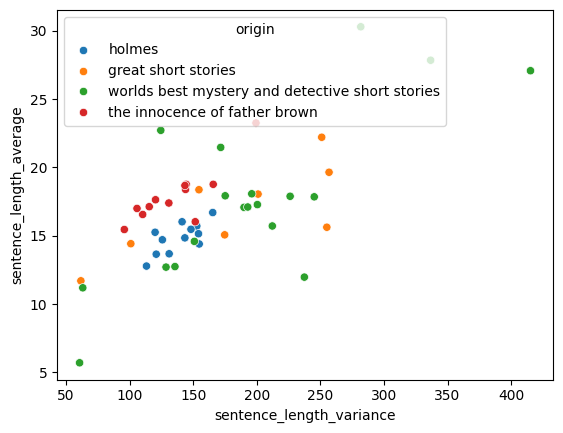

In [37]:
sns.scatterplot(data = human_stories_df, x="sentence_length_variance", y="sentence_length_average", hue="origin")

In [38]:
fig = px.scatter_3d(
    x=human_stories_df["sentence_length_average"],
    y=human_stories_df["sentence_length_variance"],
    z=human_stories_df["sentence_length_max"],
    color=human_stories_df["origin"],
    opacity=0.7
)

fig.show()

In [39]:
ai_stories_df = pd.DataFrame()

In [40]:
origins_ai = ["gemini_v1"]

stories_ai = {
    "gemini_v1": ["the_deceased_s_cipher", "the_final_chord_of_the_night", "the_mystery_of_the_locked_study", "the_secret_of_the_blue_dahlia", "the_shadow_on_the_orient_express"]
}

ids = []
filepaths = []
story_origin = []

for origin in origins_ai:
    for ai_story in stories_ai.get(origin):

        filepath = f"../data/ai/{ai_story}.txt"

        ids.append(ai_story)
        filepaths.append(filepath)
        story_origin.append(origin)

ai_stories_df.insert(0, "story_id", ids)
ai_stories_df.insert(1, "filepath", filepaths)
ai_stories_df.insert(2, "origin", story_origin)

In [41]:
ai_stories_df = add_features(ai_stories_df)
ai_stories_df

,story_id,filepath,origin,sentence_length_average,sentence_length_variance,sentence_length_max,sentence_length_min
0,the_deceased_s_cipher,../data/ai/the_deceased_s_cipher.txt,gemini_v1,19.230769,186.331361,53,0
1,the_final_chord_of_the_night,../data/ai/the_final_chord_of_the_night.txt,gemini_v1,13.428571,38.340136,28,0
2,the_mystery_of_the_locked_study,../data/ai/the_mystery_of_the_locked_study.txt,gemini_v1,17.500000,78.138889,35,0
3,the_secret_of_the_blue_dahlia,../data/ai/the_secret_of_the_blue_dahlia.txt,gemini_v1,12.611111,45.348765,30,0
4,the_shadow_on_the_orient_express,../data/ai/the_shadow_on_the_orient_express.txt,gemini_v1,16.529412,67.190311,32,0


In [42]:
fig = px.scatter_3d(
    x=ai_stories_df["sentence_length_average"],
    y=ai_stories_df["sentence_length_variance"],
    z=ai_stories_df["sentence_length_max"],
    opacity=0.7
)

fig.show()

In [43]:
fig = px.scatter_3d(
    x=pd.concat([human_stories_df, ai_stories_df])["sentence_length_average"],
    y=pd.concat([human_stories_df, ai_stories_df])["sentence_length_variance"],
    z=pd.concat([human_stories_df, ai_stories_df])["sentence_length_max"],
    color=pd.concat([human_stories_df, ai_stories_df])["origin"],
    opacity=0.7
)

fig.show()

<Axes: xlabel='sentence_length_variance', ylabel='sentence_length_max'>

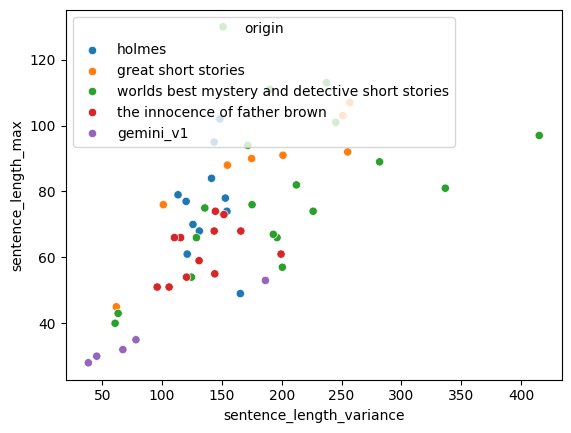

In [44]:
sns.scatterplot(data = pd.concat([human_stories_df, ai_stories_df]), x="sentence_length_variance", y="sentence_length_max", hue="origin")